## Proyecto Independiente Maven Toys


#1. Importar archivos mediante el ordenador

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving calendar.csv to calendar.csv
Saving data_dictionary.csv to data_dictionary.csv
Saving inventory.csv to inventory.csv
Saving products.csv to products.csv
Saving sales.csv to sales.csv
Saving stores.csv to stores.csv


In [ ]:
import os

os.listdir()

['.config',
 'data_dictionary.csv',
 'stores.csv',
 'products.csv',
 'calendar.csv',
 'sales.csv',
 'inventory.csv',
 'sample_data']

#2. Importar librerias necesarias

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 3. Cargar archivos


In [ ]:
sales = pd.read_csv('sales.csv')
products = pd.read_csv('products.csv')
stores = pd.read_csv('stores.csv')
inventory = pd.read_csv('inventory.csv')
calendar = pd.read_csv('calendar.csv')

In [ ]:
sales.head()

,Sale_ID,Date,Store_ID,Product_ID,Units
0,1,2022-01-01,24,4,1
1,2,2022-01-01,28,1,1
2,3,2022-01-01,6,8,1
3,4,2022-01-01,48,7,1
4,5,2022-01-01,44,18,1


In [ ]:
products.head()

,Product_ID,Product_Name,Product_Category,Product_Cost,Product_Price
0,1,Action Figure,Toys,$9.99,$15.99
1,2,Animal Figures,Toys,$9.99,$12.99
2,3,Barrel O' Slime,Art & Crafts,$1.99,$3.99
3,4,Chutes & Ladders,Games,$9.99,$12.99
4,5,Classic Dominoes,Games,$7.99,$9.99


# 4. Revisar dimensiones.

## .shape(): para revisar filas, columnas

In [ ]:
print("Sales:", sales.shape)
print("Products:", products.shape)
print("Stores:", stores.shape)
print("Inventory:", inventory.shape)
print("Calendar:", calendar.shape)

Sales: (829262, 5)
Products: (35, 5)
Stores: (50, 5)
Inventory: (1593, 3)
Calendar: (638, 1)


# 5. Revisar estructura y tipos con .info()

In [ ]:
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 829262 entries, 0 to 829261
Data columns (total 5 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   Sale_ID     829262 non-null  int64 
 1   Date        829262 non-null  object
 2   Store_ID    829262 non-null  int64 
 3   Product_ID  829262 non-null  int64 
 4   Units       829262 non-null  int64 
dtypes: int64(4), object(1)
memory usage: 31.6+ MB


In [ ]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35 entries, 0 to 34
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Product_ID        35 non-null     int64 
 1   Product_Name      35 non-null     object
 2   Product_Category  35 non-null     object
 3   Product_Cost      35 non-null     object
 4   Product_Price     35 non-null     object
dtypes: int64(1), object(4)
memory usage: 1.5+ KB


# 6. Validar nulos con .isna() y .sum()

## .isna() para detectar nulos.
### .sum() lo cuenta por columna.


In [ ]:
sales.isna().sum()

,0
Sale_ID,0
Date,0
Store_ID,0
Product_ID,0
Units,0


In [ ]:
products.isna().sum()

,0
Product_ID,0
Product_Name,0
Product_Category,0
Product_Cost,0
Product_Price,0


In [ ]:
inventory.isna().sum()

,0
Store_ID,0
Product_ID,0
Stock_On_Hand,0


# 7. Revisamos duplicados con la función: duplicated() y .sum()

In [ ]:
sales.duplicated().sum()

np.int64(0)

In [ ]:
sales['Sale_ID'].duplicated().sum()

np.int64(0)

In [ ]:
products['Product_ID'].duplicated().sum()

np.int64(0)

In [ ]:
inventory.duplicated(
    subset=['Store_ID', 'Product_ID']
).sum()

np.int64(0)

# 8. Limpiar costo y precio

In [ ]:
products['Product_Cost'] = (
    products['Product_Cost']
    .str.replace('$', '', regex=False)
    .str.strip()
    .astype(float)
)

products['Product_Price'] = (
    products['Product_Price']
    .str.replace('$', '', regex=False)
    .str.strip()
    .astype(float)
)

In [ ]:
# Validamos
products.dtypes

,0
Product_ID,int64
Product_Name,object
Product_Category,object
Product_Cost,float64
Product_Price,float64


# 9. Convertimos fechas

In [ ]:
sales['Date'] = pd.to_datetime(sales['Date'])
stores['Store_Open_Date'] = pd.to_datetime(stores['Store_Open_Date'])
calendar['Date'] = pd.to_datetime(calendar['Date'])

In [ ]:
sales.dtypes

,0
Sale_ID,int64
Date,datetime64[ns]
Store_ID,int64
Product_ID,int64
Units,int64


# 10. Creamos sales_enriched

In [ ]:
sales_enriched = sales.merge(
  products,
  on='Product_ID',
  how='inner'
)

In [ ]:
sales_enriched.head()

,Sale_ID,Date,Store_ID,Product_ID,Units,Product_Name,Product_Category,Product_Cost,Product_Price
0,1,2022-01-01,24,4,1,Chutes & Ladders,Games,9.99,12.99
1,2,2022-01-01,28,1,1,Action Figure,Toys,9.99,15.99
2,3,2022-01-01,6,8,1,Deck Of Cards,Games,3.99,6.99
3,4,2022-01-01,48,7,1,Dart Gun,Sports & Outdoors,11.99,15.99
4,5,2022-01-01,44,18,1,Lego Bricks,Toys,34.99,39.99


In [ ]:
sales_enriched['Revenue'] = (
    sales_enriched['Units']
    * sales_enriched['Product_Price']
)

sales_enriched['COGS'] = (
    sales_enriched['Units']
    * sales_enriched['Product_Cost']
)

sales_enriched['Gross_Profit'] = (
    sales_enriched['Revenue']
    - sales_enriched['COGS']
)

In [ ]:
sales_enriched[
    ['Revenue', 'COGS', 'Gross_Profit']
].describe()

,Revenue,COGS,Gross_Profit
count,829262.000000,829262.000000,829262.000000
mean,17.418587,12.578104,4.840483
std,15.522069,13.082370,4.476390
min,2.990000,1.990000,1.000000
25%,8.990000,3.990000,2.000000
50%,14.990000,9.990000,4.000000
75%,19.990000,14.990000,6.000000
max,879.780000,769.780000,150.000000


In [ ]:
sales_enriched['Units'].describe()

,Units
count,829262.000000
mean,1.315103
std,0.830701
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,30.000000


In [ ]:
sales_enriched.sort_values(
    by='Revenue',
    ascending=False
)[
    ['Sale_ID', 'Product_Name', 'Units',
     'Product_Price', 'Revenue']
].head(10)

,Sale_ID,Product_Name,Units,Product_Price,Revenue
516427,516428,Lego Bricks,22,39.99,879.78
518096,518097,Lego Bricks,21,39.99,839.79
517671,517672,Lego Bricks,21,39.99,839.79
516434,516435,Lego Bricks,20,39.99,799.80
516618,516619,Lego Bricks,20,39.99,799.80
516398,516399,Lego Bricks,19,39.99,759.81
517599,517600,Lego Bricks,18,39.99,719.82
516110,516111,Lego Bricks,17,39.99,679.83
518074,518075,Lego Bricks,17,39.99,679.83
516461,516462,Lego Bricks,17,39.99,679.83


# 11. Visulizaciones

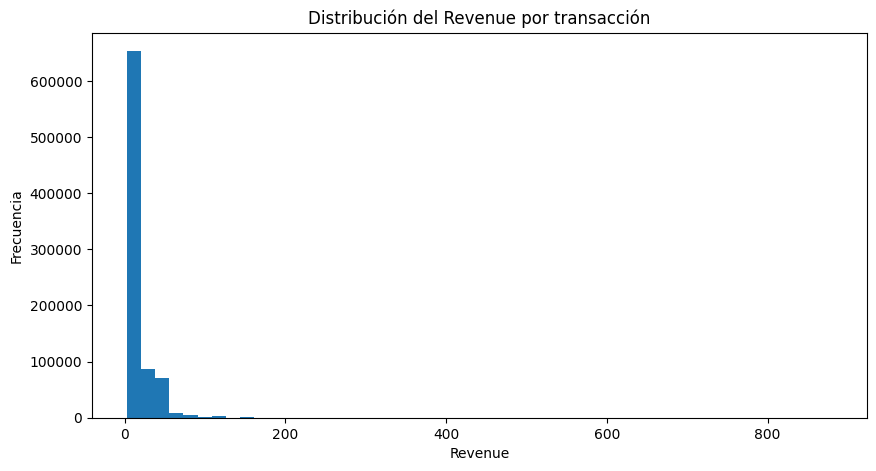

In [ ]:
# Visualizamos Revenue
plt.figure(figsize=(10, 5))

plt.hist(
    sales_enriched['Revenue'],
    bins=50
)

plt.title('Distribución del Revenue por transacción')
plt.xlabel('Revenue')
plt.ylabel('Frecuencia')

plt.show()

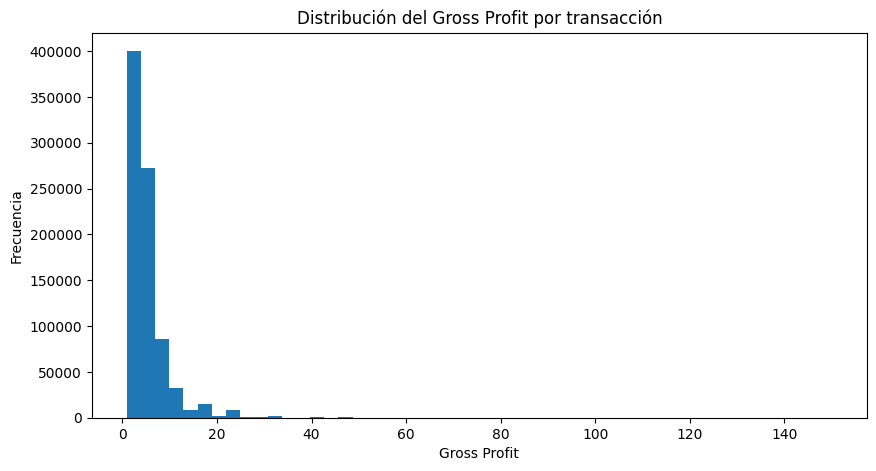

In [ ]:
# Visualizamos Gross Profit
plt.figure(figsize=(10, 5))

plt.hist(
    sales_enriched['Gross_Profit'],
    bins=50
)

plt.title('Distribución del Gross Profit por transacción')
plt.xlabel('Gross Profit')
plt.ylabel('Frecuencia')

plt.show()

# 12. Detectar posibles valores atípicos.
## Uso de Interquartile Range(IQR)

In [ ]:
# Para Revenue
Q1 = sales_enriched['Revenue'].quantile(0.25)
Q3 = sales_enriched['Revenue'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Límite inferior:", lower_bound)
print("Límite superior:", upper_bound)

Q1: 8.99
Q3: 19.99
IQR: 10.999999999999998
Límite inferior: -7.509999999999996
Límite superior: 36.489999999999995


In [ ]:
revenue_outliers = sales_enriched[
    (sales_enriched['Revenue'] < lower_bound) |
    (sales_enriched['Revenue'] > upper_bound)
]

print("Número de posibles outliers:",
      len(revenue_outliers))

print(
    "Porcentaje:",
    round(
        len(revenue_outliers)
        / len(sales_enriched)
        * 100,
        2
    ),
    "%"
)

Número de posibles outliers: 89908
Porcentaje: 10.84 %


# 13. Correlaciones
## Pearson y Spearman

In [ ]:
corr_columns = [
    'Units',
    'Product_Cost',
    'Product_Price',
    'Revenue',
    'COGS',
    'Gross_Profit'
]

correlation_matrix = (
    sales_enriched[corr_columns]
    .corr(method='pearson')
)

correlation_matrix

,Units,Product_Cost,Product_Price,Revenue,COGS,Gross_Profit
Units,1.000000,-0.083454,-0.096340,0.544936,0.453972,0.562843
Product_Cost,-0.083454,1.000000,0.961101,0.635769,0.719628,0.101423
Product_Price,-0.096340,0.961101,1.000000,0.658062,0.685408,0.278734
Revenue,0.544936,0.635769,0.658062,1.000000,0.965317,0.646378
COGS,0.453972,0.719628,0.685408,0.965317,1.000000,0.424749
Gross_Profit,0.562843,0.101423,0.278734,0.646378,0.424749,1.000000


In [ ]:
print(
    "Units vs Revenue:",
    sales_enriched['Units'].corr(
        sales_enriched['Revenue']
    )
)

print(
    "Product Price vs Revenue:",
    sales_enriched['Product_Price'].corr(
        sales_enriched['Revenue']
    )
)

print(
    "Revenue vs Gross Profit:",
    sales_enriched['Revenue'].corr(
        sales_enriched['Gross_Profit']
    )
)

Units vs Revenue: 0.5449359549008775
Product Price vs Revenue: 0.6580618865553866
Revenue vs Gross Profit: 0.6463775471372314


In [ ]:
spearman_matrix = (
    sales_enriched[corr_columns]
    .corr(method='spearman')
)

spearman_matrix

,Units,Product_Cost,Product_Price,Revenue,COGS,Gross_Profit
Units,1.000000,-0.118845,-0.119784,0.355964,0.292048,0.388585
Product_Cost,-0.118845,1.000000,0.929776,0.800128,0.894326,0.212183
Product_Price,-0.119784,0.929776,1.000000,0.860996,0.834347,0.483697
Revenue,0.355964,0.800128,0.860996,1.000000,0.941020,0.639975
COGS,0.292048,0.894326,0.834347,0.941020,1.000000,0.378138
Gross_Profit,0.388585,0.212183,0.483697,0.639975,0.378138,1.000000


In [ ]:
print(
    "Units vs Revenue - Spearman:",
    sales_enriched['Units'].corr(
        sales_enriched['Revenue'],
        method='spearman'
    )
)

print(
    "Product Price vs Revenue - Spearman:",
    sales_enriched['Product_Price'].corr(
        sales_enriched['Revenue'],
        method='spearman'
    )
)

print(
    "Revenue vs Gross Profit - Spearman:",
    sales_enriched['Revenue'].corr(
        sales_enriched['Gross_Profit'],
        method='spearman'
    )
)

Units vs Revenue - Spearman: 0.3559638396625231
Product Price vs Revenue - Spearman: 0.8609958360511835
Revenue vs Gross Profit - Spearman: 0.6399754391345736


In [ ]:
sample = sales_enriched.sample(
    n=10000,
    random_state=42
)

# 14. Gráficos

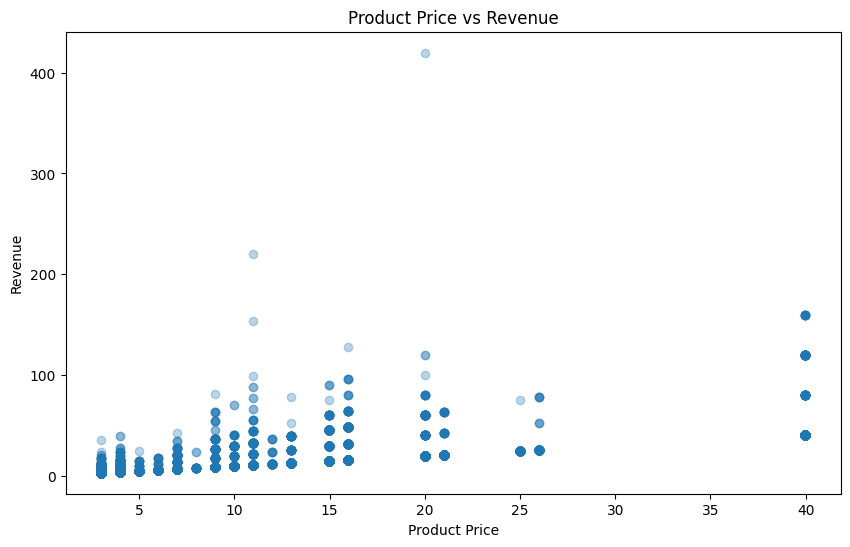

In [ ]:
plt.figure(figsize=(10, 6))

plt.scatter(
    sample['Product_Price'],
    sample['Revenue'],
    alpha=0.3
)

plt.title('Product Price vs Revenue')
plt.xlabel('Product Price')
plt.ylabel('Revenue')

plt.show()

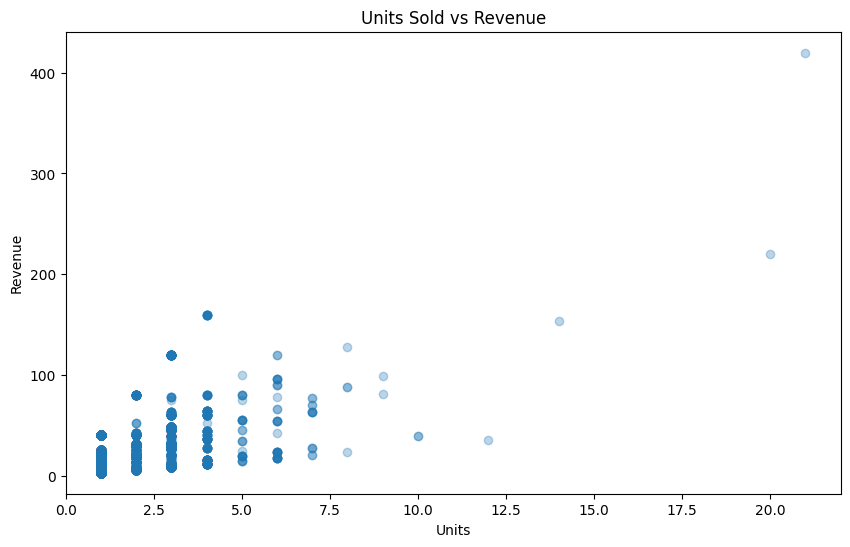

In [ ]:
plt.figure(figsize=(10, 6))

plt.scatter(
    sample['Units'],
    sample['Revenue'],
    alpha=0.3
)

plt.title('Units Sold vs Revenue')
plt.xlabel('Units')
plt.ylabel('Revenue')

plt.show()

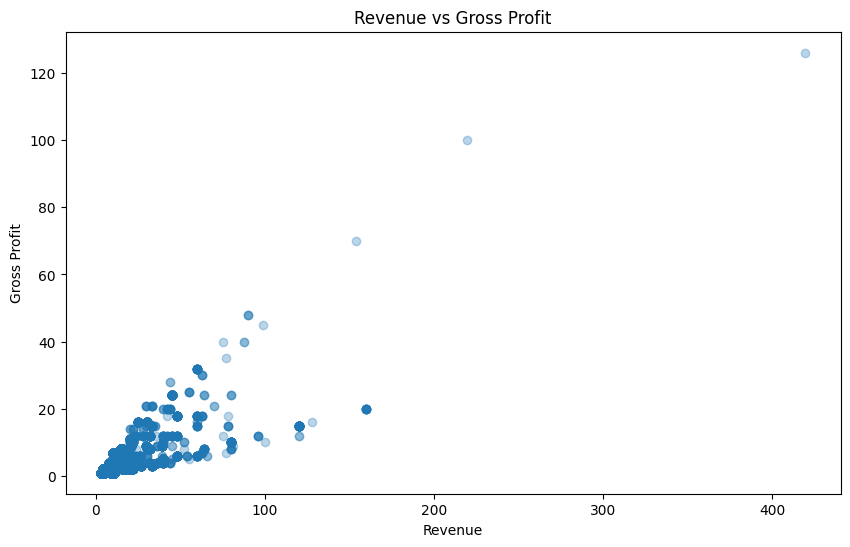

In [ ]:
plt.figure(figsize=(10, 6))

plt.scatter(
    sample['Revenue'],
    sample['Gross_Profit'],
    alpha=0.3
)

plt.title('Revenue vs Gross Profit')
plt.xlabel('Revenue')
plt.ylabel('Gross Profit')

plt.show()

In [ ]:
category_performance = (
    sales_enriched
    .groupby('Product_Category', as_index=False)
    .agg(
        Revenue=('Revenue', 'sum'),
        Gross_Profit=('Gross_Profit', 'sum'),
        Units_Sold=('Units', 'sum')
    )
)

category_performance['Gross_Margin_Pct'] = (
    category_performance['Gross_Profit']
    / category_performance['Revenue']
    * 100
)

category_performance = (
    category_performance
    .sort_values('Revenue', ascending=False)
)

category_performance

,Product_Category,Revenue,Gross_Profit,Units_Sold,Gross_Margin_Pct
4,Toys,5093241.00,1079527.0,267200,21.195286
0,Art & Crafts,2705364.26,753354.0,325574,27.846675
1,Electronics,2246771.25,1001437.0,134075,44.572272
2,Games,2226836.27,673993.0,194673,30.266841
3,Sports & Outdoors,2172359.57,505718.0,169043,23.279664


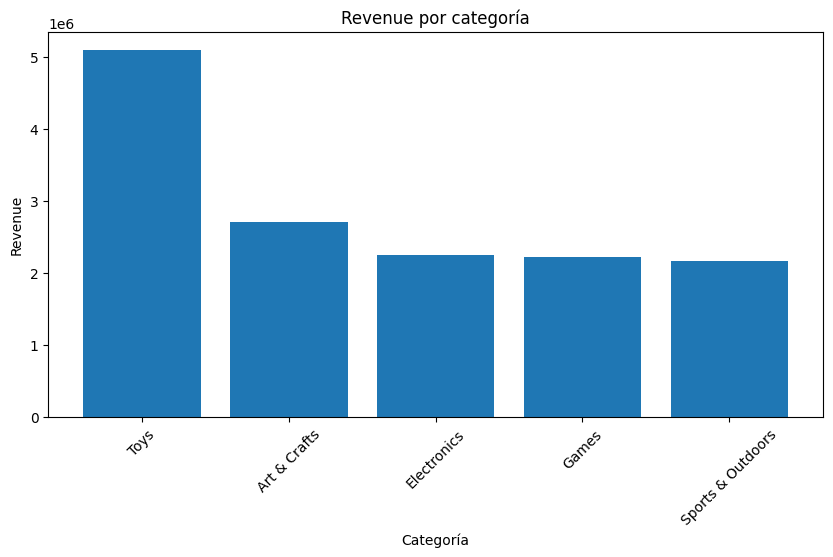

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    category_performance['Product_Category'],
    category_performance['Revenue']
)

plt.title('Revenue por categoría')
plt.xlabel('Categoría')
plt.ylabel('Revenue')
plt.xticks(rotation=45)

plt.show()

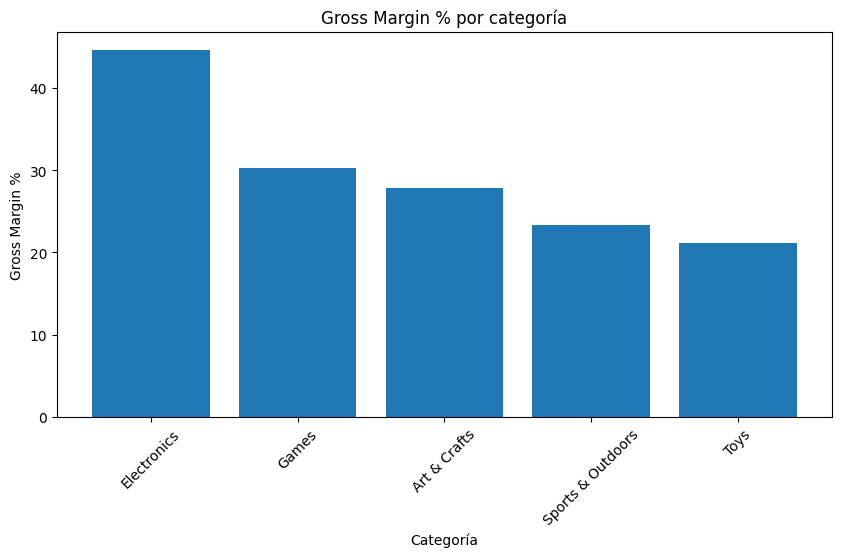

In [ ]:
category_margin = (
    category_performance
    .sort_values('Gross_Margin_Pct', ascending=False)
)

plt.figure(figsize=(10, 5))

plt.bar(
    category_margin['Product_Category'],
    category_margin['Gross_Margin_Pct']
)

plt.title('Gross Margin % por categoría')
plt.xlabel('Categoría')
plt.ylabel('Gross Margin %')
plt.xticks(rotation=45)

plt.show()

In [ ]:
category_performance['Revenue_Share_Pct'] = (
    category_performance['Revenue']
    / category_performance['Revenue'].sum()
    * 100
)

category_performance['Profit_Share_Pct'] = (
    category_performance['Gross_Profit']
    / category_performance['Gross_Profit'].sum()
    * 100
)

category_performance[
    [
        'Product_Category',
        'Revenue',
        'Revenue_Share_Pct',
        'Gross_Profit',
        'Profit_Share_Pct',
        'Gross_Margin_Pct'
    ]
].round(2)

,Product_Category,Revenue,Revenue_Share_Pct,Gross_Profit,Profit_Share_Pct,Gross_Margin_Pct
4,Toys,5093241.00,35.26,1079527.0,26.89,21.20
0,Art & Crafts,2705364.26,18.73,753354.0,18.77,27.85
1,Electronics,2246771.25,15.55,1001437.0,24.95,44.57
2,Games,2226836.27,15.42,673993.0,16.79,30.27
3,Sports & Outdoors,2172359.57,15.04,505718.0,12.60,23.28


In [ ]:
## Ventas por producto.
product_sales = (
    sales_enriched
    .groupby(
        ['Product_ID', 'Product_Name', 'Product_Category'],
        as_index=False
    )
    .agg(
        Revenue=('Revenue', 'sum'),
        Gross_Profit=('Gross_Profit', 'sum'),
        Units_Sold=('Units', 'sum')
    )
)

In [ ]:
product_sales.head()

,Product_ID,Product_Name,Product_Category,Revenue,Gross_Profit,Units_Sold
0,1,Action Figure,Toys,926748.42,347748.0,57958
1,2,Animal Figures,Toys,507766.11,117267.0,39089
2,3,Barrel O' Slime,Art & Crafts,365735.37,183326.0,91663
3,4,Chutes & Ladders,Games,49738.71,11487.0,3829
4,5,Classic Dominoes,Games,44665.29,8942.0,4471


In [ ]:
inventory_product = (
    inventory
    .groupby('Product_ID', as_index=False)
    .agg(
        Total_Stock=('Stock_On_Hand', 'sum')
    )
)

In [ ]:
inventory_product.head()

,Product_ID,Total_Stock
0,1,614
1,2,835
2,3,1282
3,4,255
4,5,241


In [ ]:
product_analysis = product_sales.merge(
    inventory_product,
    on='Product_ID',
    how='left'
)

In [ ]:
product_analysis.head()

,Product_ID,Product_Name,Product_Category,Revenue,Gross_Profit,Units_Sold,Total_Stock
0,1,Action Figure,Toys,926748.42,347748.0,57958,614
1,2,Animal Figures,Toys,507766.11,117267.0,39089,835
2,3,Barrel O' Slime,Art & Crafts,365735.37,183326.0,91663,1282
3,4,Chutes & Ladders,Games,49738.71,11487.0,3829,255
4,5,Classic Dominoes,Games,44665.29,8942.0,4471,241


In [ ]:
recent_sales = (
    sales_enriched[
        (sales_enriched['Date'] >= '2023-07-01') &
        (sales_enriched['Date'] <= '2023-09-30')
    ]
    .groupby('Product_ID', as_index=False)
    .agg(
        Units_Sold_Last_3M=('Units', 'sum')
    )
)

recent_sales['Avg_Monthly_Units'] = (
    recent_sales['Units_Sold_Last_3M'] / 3
)

In [ ]:
product_analysis = product_analysis.merge(
    recent_sales[
        ['Product_ID', 'Avg_Monthly_Units']
    ],
    on='Product_ID',
    how='left'
)

In [ ]:
product_analysis['Months_Of_Stock'] = (
    product_analysis['Total_Stock']
    / product_analysis['Avg_Monthly_Units']
)

In [ ]:
product_analysis[
    [
        'Product_Name',
        'Revenue',
        'Gross_Profit',
        'Units_Sold',
        'Total_Stock',
        'Avg_Monthly_Units',
        'Months_Of_Stock'
    ]
].sort_values(
    'Revenue',
    ascending=False
).head(10)

,Product_Name,Revenue,Gross_Profit,Units_Sold,Total_Stock,Avg_Monthly_Units,Months_Of_Stock
17,Lego Bricks,2388882.63,298685.0,59737,1118,2835.000000,0.394356
5,Colorbuds,1564476.32,834944.0,104368,1159,3098.666667,0.374032
18,Magic Sand,968962.02,121196.0,60598,1922,4806.666667,0.399861
0,Action Figure,926748.42,347748.0,57958,614,1590.000000,0.386164
29,Rubik's Cube,912983.28,91344.0,45672,1497,1843.333333,0.812116
7,Deck Of Cards,587397.66,252102.0,84034,2738,3647.000000,0.750754
30,Splash Balls,541629.52,60248.0,60248,893,2725.666667,0.327626
23,Nerf Gun,530594.57,132715.0,26543,1212,1670.666667,0.725459
1,Animal Figures,507766.11,117267.0,39089,835,2051.000000,0.407118
6,Dart Gun,505092.12,126352.0,31588,776,1172.333333,0.661928


In [ ]:
## Mediana Revenue
revenue_median = product_analysis['Revenue'].median()
revenue_median

308352.72000000003

In [ ]:
product_analysis['Priority_Status'] = np.select(
    [
        (product_analysis['Revenue'] >= revenue_median) &
        (product_analysis['Months_Of_Stock'] < 0.5),

        (product_analysis['Revenue'] >= revenue_median) &
        (product_analysis['Months_Of_Stock'] >= 0.5),

        (product_analysis['Revenue'] < revenue_median) &
        (product_analysis['Months_Of_Stock'] < 0.5)
    ],
    [
        'High Priority',
        'Monitor',
        'Low Revenue / Low Coverage'
    ],
    default='Low Priority'
)

In [ ]:
product_analysis[
    [
        'Product_Name',
        'Revenue',
        'Gross_Profit',
        'Months_Of_Stock',
        'Priority_Status'
    ]
].sort_values(
    ['Priority_Status', 'Revenue'],
    ascending=[True, False]
)

,Product_Name,Revenue,Gross_Profit,Months_Of_Stock,Priority_Status
17,Lego Bricks,2388882.63,298685.0,0.394356,High Priority
5,Colorbuds,1564476.32,834944.0,0.374032,High Priority
18,Magic Sand,968962.02,121196.0,0.399861,High Priority
0,Action Figure,926748.42,347748.0,0.386164,High Priority
30,Splash Balls,541629.52,60248.0,0.327626,High Priority
1,Animal Figures,507766.11,117267.0,0.407118,High Priority
8,Dino Egg,420213.64,38236.0,0.203427,High Priority
2,Barrel O' Slime,365735.37,183326.0,0.268482,High Priority
20,Mini Ping Pong Set,335703.96,100812.0,0.471062,High Priority
24,PlayDoh Can,308352.72,103128.0,0.337686,High Priority


In [ ]:
priority_summary = (
    product_analysis
    .groupby('Priority_Status', as_index=False)
    .agg(
        Product_Count=('Product_ID', 'count'),
        Total_Revenue=('Revenue', 'sum'),
        Total_Gross_Profit=('Gross_Profit', 'sum')
    )
)

priority_summary

,Priority_Status,Product_Count,Total_Revenue,Total_Gross_Profit
0,High Priority,10,8328470.71,2205590.0
1,Low Priority,13,1339273.27,428978.0
2,Low Revenue / Low Coverage,4,528193.95,218964.0
3,Monitor,8,4248634.42,1160497.0


In [ ]:
priority_summary['Revenue_Share_Pct'] = (
    priority_summary['Total_Revenue']
    / priority_summary['Total_Revenue'].sum()
    * 100
)

priority_summary['Profit_Share_Pct'] = (
    priority_summary['Total_Gross_Profit']
    / priority_summary['Total_Gross_Profit'].sum()
    * 100
)

priority_summary.round(2)

,Priority_Status,Product_Count,Total_Revenue,Total_Gross_Profit,Revenue_Share_Pct,Profit_Share_Pct
0,High Priority,10,8328470.71,2205590.0,57.66,54.95
1,Low Priority,13,1339273.27,428978.0,9.27,10.69
2,Low Revenue / Low Coverage,4,528193.95,218964.0,3.66,5.45
3,Monitor,8,4248634.42,1160497.0,29.41,28.91


# Hallazgos e Insights

## 1. Distribución de las transacciones. Revenue presenta asimetría positiva. El IQR detectó aproximadamente 10.84% de posibles outliers, pero comprobamos que los valores extremos corresponden principalmente a compras válidas de varias unidades, por lo que no se eliminaron.
## 2. Precio, unidades e ingresos. Spearman mostró una relación fuerte entre Product_Price y Revenue (0.861), mientras que Units presentó una relación más débil (0.356). El precio parece estar más consistentemente asociado con el ranking de Revenue transaccional.
## 3. Revenue y beneficio. Revenue y Gross Profit mantienen una relación positiva relativamente estable —Pearson ≈ 0.646, Spearman ≈ 0.640— pero la relación está lejos de ser perfecta debido a diferencias de margen entre productos.
## 4. Categorías. Toys genera 35.26% del Revenue pero solamente 26.89% del Gross Profit. Electronics genera apenas 15.55% del Revenue, pero aporta 24.95% del Gross Profit, debido a su margen de 44.57%.
## 5. Inventario. Varios productos de gran importancia comercial presentan menos de medio mes de cobertura.
## 6. Priorización. Los 10 productos High Priority concentran 57.66% del Revenue y 54.95% del Gross Profit, lo que los convierte en el principal grupo a revisar desde el punto de vista de abastecimiento.